# Autoencoders and VAEs on MNIST

**Reid Sendroff**

1. A linear autoencoder that compresses 3-D data to 2-D codings
2. A stacked (784 -> 128 -> 32) autoencoder on MNIST
3. Out-of-distribution check: reconstruction error on Fashion-MNIST vs. MNIST
4. t-SNE of the 32-D learned codings
5. Convolutional autoencoders trained with input dropout at 0.10 and 0.20
6. A variational autoencoder with a 2-D latent space and latent interpolation from a 3 to a 7

## 1. Linear autoencoder: 3-D -> 2-D

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

In [5]:
import numpy as np
np.random.seed(4)
def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
  angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5
  data = np.empty((m, 3))
  data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2
  data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2
  data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)
  return data
X_train = generate_3d_data(60)
X_train = X_train - X_train.mean(axis=0, keepdims=True)

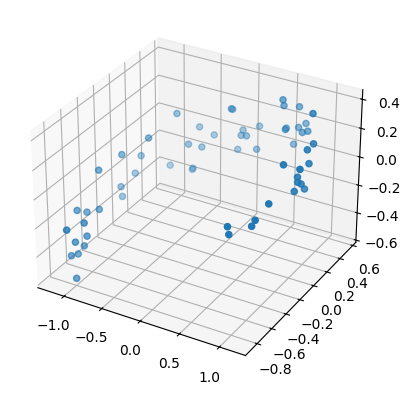

In [8]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_train[:,0], X_train[:,1], X_train[:,2])


Training MSE: 0.0033918351400643587
Validation MSE: 0.004621787462383509


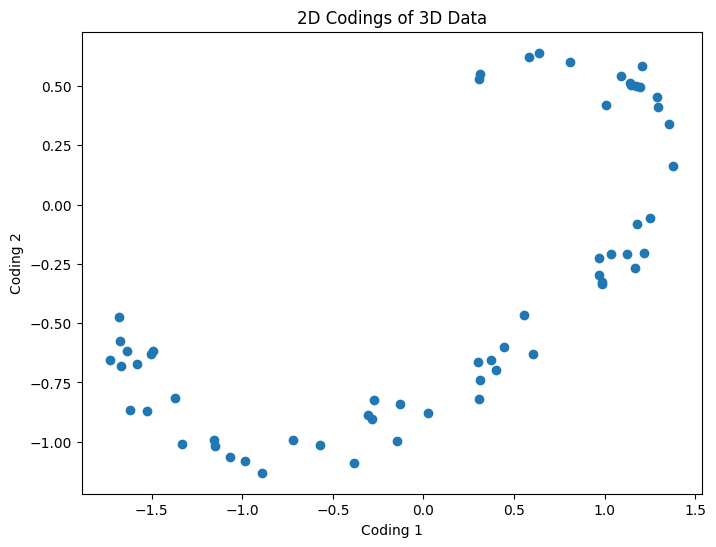

In [9]:
X_val = generate_3d_data(20)
X_val = X_val - X_val.mean(axis=0, keepdims=True)

X_train_3d = torch.tensor(X_train, dtype=torch.float32)
X_val_3d = torch.tensor(X_val, dtype=torch.float32)

autoencoder_3d = nn.Sequential(
    nn.Linear(3, 2),
    nn.Linear(2, 3)
)

optimizer_3d = torch.optim.NAdam(autoencoder_3d.parameters(), lr=0.01)
mse_3d = nn.MSELoss()

for epoch in range(300):
  optimizer_3d.zero_grad()
  reconstructions_3d = autoencoder_3d(X_train_3d)
  loss_3d = mse_3d(reconstructions_3d, X_train_3d)
  loss_3d.backward()
  optimizer_3d.step()

with torch.no_grad():
  val_loss_3d = mse_3d(autoencoder_3d(X_val_3d), X_val_3d)
  codings_3d = autoencoder_3d[0](X_train_3d).numpy()

print("Training MSE:", loss_3d.item())
print("Validation MSE:", val_loss_3d.item())

plt.figure(figsize=(8, 6))
plt.scatter(codings_3d[:, 0], codings_3d[:, 1])
plt.xlabel("Coding 1")
plt.ylabel("Coding 2")
plt.title("2D Codings of 3D Data")
plt.show()

## 2. Stacked autoencoder on MNIST

In [12]:
import torch
from torchvision import datasets, transforms
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=64, shuffle=False)


In [13]:
import torchvision.datasets as datasets

# 1. Download/Load the PyTorch MNIST training set
mnist_trainset = datasets.MNIST(root='./data', train=True, download=True)

# 2. Extract and convert images and labels to NumPy
# Images shape will be (60000, 28, 28), Labels shape will be (60000,)
train_images = mnist_trainset.data.numpy()
train_labels = mnist_trainset.targets.numpy()

print(type(train_images), train_images.shape)
X_train = train_images

<class 'numpy.ndarray'> (60000, 28, 28)


In [14]:
X_test = test_set.data.numpy()
print(type(X_test))
print(X_test.shape)

<class 'numpy.ndarray'>
(10000, 28, 28)


In [16]:
torch.manual_seed(42)

In [17]:
# create the autoencoder
stacked_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1*28*28, 128), nn.ReLU(),
    nn.Linear(128,32), nn.ReLU()
)

stacked_decoder = nn.Sequential(
    nn.Linear(32,128), nn.ReLU(),
    nn.Linear(128,1*28*28), nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1,28,28))
)

stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder)

In [18]:
X_train_tensor = torch.from_numpy(X_train).to(torch.float32)
X_train_tensor = X_train_tensor/255.0
X_test_tensor = torch.from_numpy(X_test).to(torch.float32)
X_test_tensor = X_test_tensor/255.0
# print(f"x_train_tensor shape: {X_train_tensor.shape}")
# X_test_tensor = X_train_tensor.unsqueeze(0)
# print(f"x_train_tensor shape: {X_train_tensor.shape}")
# REVIEW:
print("before")
print(X_train_tensor.shape)
# add # of channnels to the shape
# (B, C, H, W)
X_train_tensor = X_train_tensor.unsqueeze(1)
print("after")
print(X_train_tensor.shape)
print(X_train_tensor.shape)
X_test_tensor = X_test_tensor.unsqueeze(1)
assert X_test_tensor.shape[1:] == X_train_tensor.shape[1:]
print("\n\n=====")
print(f"X_train_tensor shape: {X_train_tensor.shape}")
print(f"X_test_tensor shape: {X_test_tensor.shape}")



before
torch.Size([60000, 28, 28])
after
torch.Size([60000, 1, 28, 28])
torch.Size([60000, 1, 28, 28])


=====
X_train_tensor shape: torch.Size([60000, 1, 28, 28])
X_test_tensor shape: torch.Size([10000, 1, 28, 28])


In [20]:
import torch.optim as optim

In [22]:
optimizer = optim.NAdam(stacked_ae.parameters(), lr=1e-3)
mse = nn.MSELoss()
epochs = 5

In [23]:
from torch.utils.data import DataLoader, TensorDataset

In [24]:
X_train_loader = DataLoader(
    dataset = TensorDataset(X_train_tensor, X_train_tensor),
    batch_size=32,
    shuffle=True,
    num_workers=2,
)

In [25]:
for epoch in range(epochs):
  total_loss = 0
  for batch_idx, (x_batch, y_batch) in enumerate(X_train_loader):
    optimizer.zero_grad()
    preds = stacked_ae(x_batch)
    loss = mse(preds, y_batch)

    total_loss += loss.item()
    loss.backward()
    optimizer.step()
  print(f"epoch {epoch+1} loss {total_loss:.4}")

epoch 1 loss 55.5
epoch 2 loss 27.37
epoch 3 loss 22.77
epoch 4 loss 20.73
epoch 5 loss 19.4


In [26]:
print("Minimum pixel:", X_train_tensor.min().item())
print("Maximum pixel:", X_train_tensor.max().item())
print("Input shape:", X_train_tensor.shape)
print("Output activation:", stacked_decoder)

Minimum pixel: 0.0
Maximum pixel: 1.0
Input shape: torch.Size([60000, 1, 28, 28])
Output activation: Sequential(
  (0): Linear(in_features=32, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=784, bias=True)
  (3): Sigmoid()
  (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
)


## 3. Out-of-distribution reconstruction: Fashion-MNIST vs. MNIST

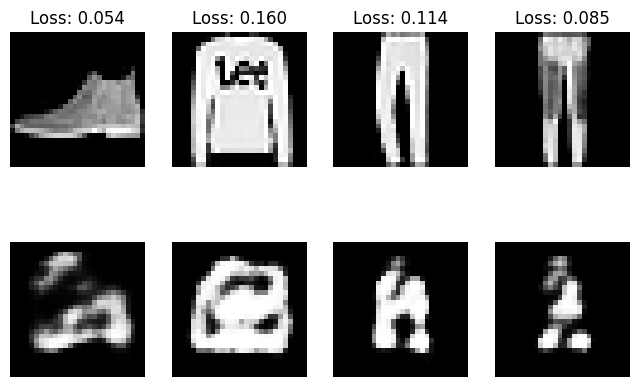

Fashion MNIST MSE: 0.10345424618571997
MNIST MSE: 0.007246431545354426


In [27]:
from torchvision.datasets import FashionMNIST

fashion = FashionMNIST(root="./data", train=False, download=True)
fashion_images = fashion.data[:4].float().unsqueeze(1) / 255.0
mnist_images = X_test_tensor[:4]

stacked_ae.eval()
with torch.no_grad():
    fashion_preds = stacked_ae(fashion_images)
    mnist_preds = stacked_ae(mnist_images)

fashion_losses = [mse(fashion_preds[i], fashion_images[i]).item() for i in range(4)]
mnist_losses = [mse(mnist_preds[i], mnist_images[i]).item() for i in range(4)]

fig, axes = plt.subplots(2, 4, figsize=(8, 5))

for i in range(4):
    axes[0, i].imshow(fashion_images[i].squeeze(), cmap="gray")
    axes[1, i].imshow(fashion_preds[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
    axes[0, i].set_title(f"Loss: {fashion_losses[i]:.3f}")

plt.show()

print("Fashion MNIST MSE:", sum(fashion_losses) / len(fashion_losses))
print("MNIST MSE:", sum(mnist_losses) / len(mnist_losses))

## 4. t-SNE of the learned 32-D codings

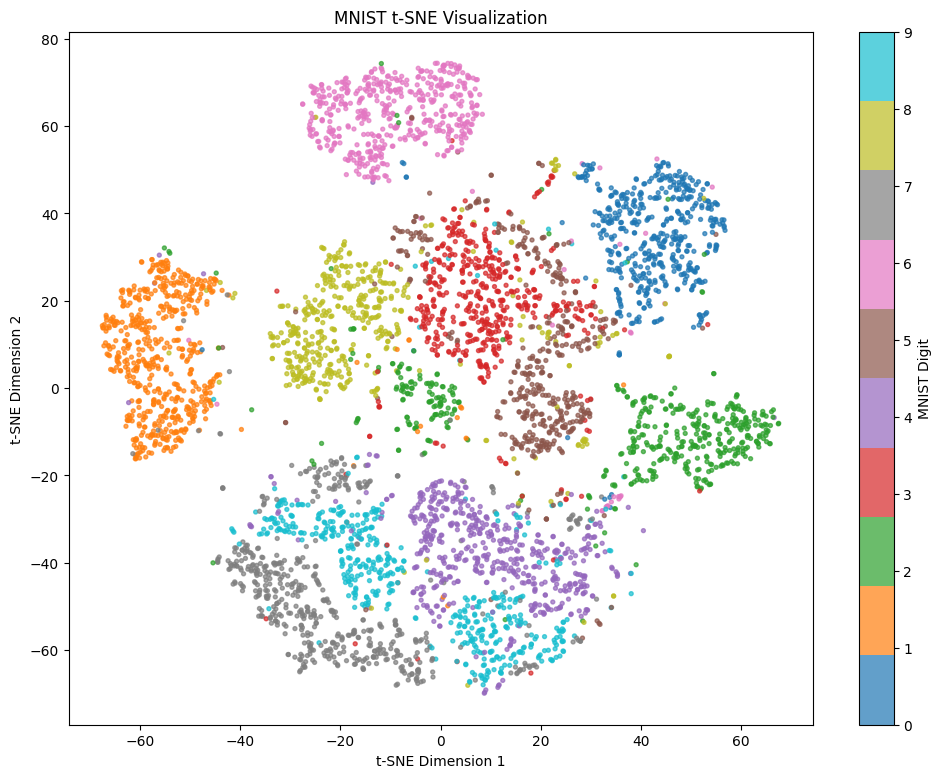

In [32]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
import torch

X_subset = X_train_tensor[:5000]
labels = train_labels[:5000]
stacked_encoder.eval()

with torch.no_grad():
    codings = stacked_encoder(X_subset)

# Reduce from 32 dimensions to 2 using t-SNE
tsne = TSNE(
    n_components=2,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_2D = tsne.fit_transform(codings.cpu().numpy())




plt.figure(figsize=(12, 9))

plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=labels,
    cmap="tab10",
    s=8,
    alpha=0.7
)

plt.colorbar(ticks=range(10), label="MNIST Digit")
plt.title("MNIST t-SNE Visualization")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

## 5. Convolutional autoencoder with input dropout (0.20 vs. 0.10)

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset


In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def create_denoising_ae(dropout_rate):
    encoder = nn.Sequential(
        nn.Dropout(dropout_rate),

        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

    decoder = nn.Sequential(
        nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
        nn.ReLU(),

        nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2),
        nn.Sigmoid()
    )

    return nn.Sequential(encoder, decoder).to(device)

In [35]:
X_train_loader = DataLoader(
    TensorDataset(X_train_tensor, X_train_tensor),
    batch_size=64,
    shuffle=True
)

torch.manual_seed(42)

model_20 = create_denoising_ae(0.20)
optimizer = optim.NAdam(model_20.parameters(), lr=1e-3)
mse = nn.MSELoss()

epochs = 10

for epoch in range(epochs):
    model_20.train()
    total_loss = 0

    for x_batch, y_batch in X_train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        preds = model_20(x_batch)
        loss = mse(preds, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}: MSE = {total_loss / len(X_train_loader):.5f}")

Epoch 1: MSE = 0.02502
Epoch 2: MSE = 0.00643
Epoch 3: MSE = 0.00551
Epoch 4: MSE = 0.00507
Epoch 5: MSE = 0.00479
Epoch 6: MSE = 0.00461
Epoch 7: MSE = 0.00448
Epoch 8: MSE = 0.00438
Epoch 9: MSE = 0.00427
Epoch 10: MSE = 0.00419


In [36]:
torch.manual_seed(42)

model_10 = create_denoising_ae(0.10)
optimizer = optim.NAdam(model_10.parameters(), lr=1e-3)

for epoch in range(epochs):
    model_10.train()
    total_loss = 0

    for x_batch, y_batch in X_train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        preds = model_10(x_batch)
        loss = mse(preds, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}: MSE = {total_loss / len(X_train_loader):.5f}")

Epoch 1: MSE = 0.02420
Epoch 2: MSE = 0.00553
Epoch 3: MSE = 0.00470
Epoch 4: MSE = 0.00428
Epoch 5: MSE = 0.00402
Epoch 6: MSE = 0.00383
Epoch 7: MSE = 0.00369
Epoch 8: MSE = 0.00358
Epoch 9: MSE = 0.00349
Epoch 10: MSE = 0.00342


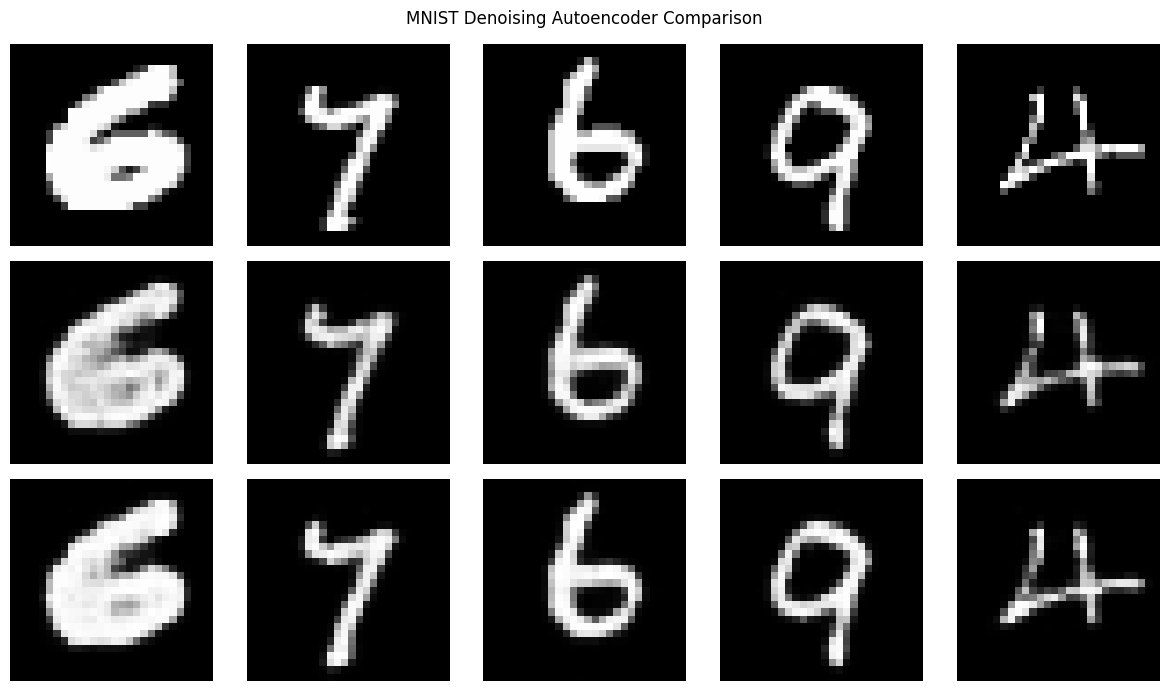

In [37]:
# Select 5 random images
torch.manual_seed(42)
indices = torch.randperm(len(X_train_tensor))[:5]
samples = X_train_tensor[indices].to(device)

model_20.eval()
model_10.eval()

with torch.no_grad():
    preds_20 = model_20(samples)
    preds_10 = model_10(samples)

fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i in range(5):
    axes[0, i].imshow(samples[i].cpu().squeeze(), cmap="gray")
    axes[1, i].imshow(preds_20[i].cpu().squeeze(), cmap="gray")
    axes[2, i].imshow(preds_10[i].cpu().squeeze(), cmap="gray")

    for row in range(3):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Dropout 0.20")
axes[2, 0].set_ylabel("Dropout 0.10")

plt.suptitle("MNIST Denoising Autoencoder Comparison")
plt.tight_layout()
plt.show()

In [38]:
print("Dropout 0.20 MSE:", mse(preds_20, samples).item())
print("Dropout 0.10 MSE:", mse(preds_10, samples).item())

Dropout 0.20 MSE: 0.006916787009686232
Dropout 0.10 MSE: 0.003394651459529996


## 6. Variational autoencoder (2-D latent) and latent interpolation

In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim * 2)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def encode(self, x):
        result = self.encoder(x)
        mu, logvar = result.chunk(2, dim=1)
        return mu, logvar

    def sample(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)
        return mu + noise * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.sample(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar

In [40]:
def vae_loss(preds, targets):
    reconstructed, mu, logvar = preds

    reconstruction_loss = F.mse_loss(reconstructed, targets)

    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(),dim=1).mean()

    return reconstruction_loss + kl_loss / 784

In [41]:
torch.manual_seed(42)

vae = VAE(latent_dim=2).to(device)

optimizer = optim.NAdam(vae.parameters(), lr=1e-3)

epochs = 20

for epoch in range(epochs):
    vae.train()
    total_loss = 0

    for x_batch, _ in X_train_loader:
        x_batch = x_batch.to(device)

        optimizer.zero_grad()

        preds = vae(x_batch)
        loss = vae_loss(preds, x_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}: Loss = {total_loss / len(X_train_loader):.5f}")

Epoch 1/20: Loss = 0.06450
Epoch 2/20: Loss = 0.05517
Epoch 3/20: Loss = 0.05339
Epoch 4/20: Loss = 0.05248
Epoch 5/20: Loss = 0.05178
Epoch 6/20: Loss = 0.05121
Epoch 7/20: Loss = 0.05081
Epoch 8/20: Loss = 0.05046
Epoch 9/20: Loss = 0.05018
Epoch 10/20: Loss = 0.04996
Epoch 11/20: Loss = 0.04979
Epoch 12/20: Loss = 0.04962
Epoch 13/20: Loss = 0.04945
Epoch 14/20: Loss = 0.04930
Epoch 15/20: Loss = 0.04916
Epoch 16/20: Loss = 0.04903
Epoch 17/20: Loss = 0.04890
Epoch 18/20: Loss = 0.04879
Epoch 19/20: Loss = 0.04870
Epoch 20/20: Loss = 0.04860


In [42]:
torch.manual_seed(42)

labels = torch.as_tensor(train_labels).flatten()

idx3 = torch.where(labels == 3)[0]
idx7 = torch.where(labels == 7)[0]

i3 = idx3[torch.randint(len(idx3), (1,))].item()
i7 = idx7[torch.randint(len(idx7), (1,))].item()

images = X_train_tensor[[i3, i7]].to(device)

vae.eval()

with torch.no_grad():
    mu, logvar = vae.encode(images)
    weights = torch.linspace(0, 1, 20, device=device).unsqueeze(1)
    codings = torch.lerp(mu[0], mu[1], weights)
    generated = vae.decode(codings)

print("Latent shape:", codings.shape)
print("Generated images:", generated.shape)

Latent shape: torch.Size([20, 2])
Generated images: torch.Size([20, 1, 28, 28])


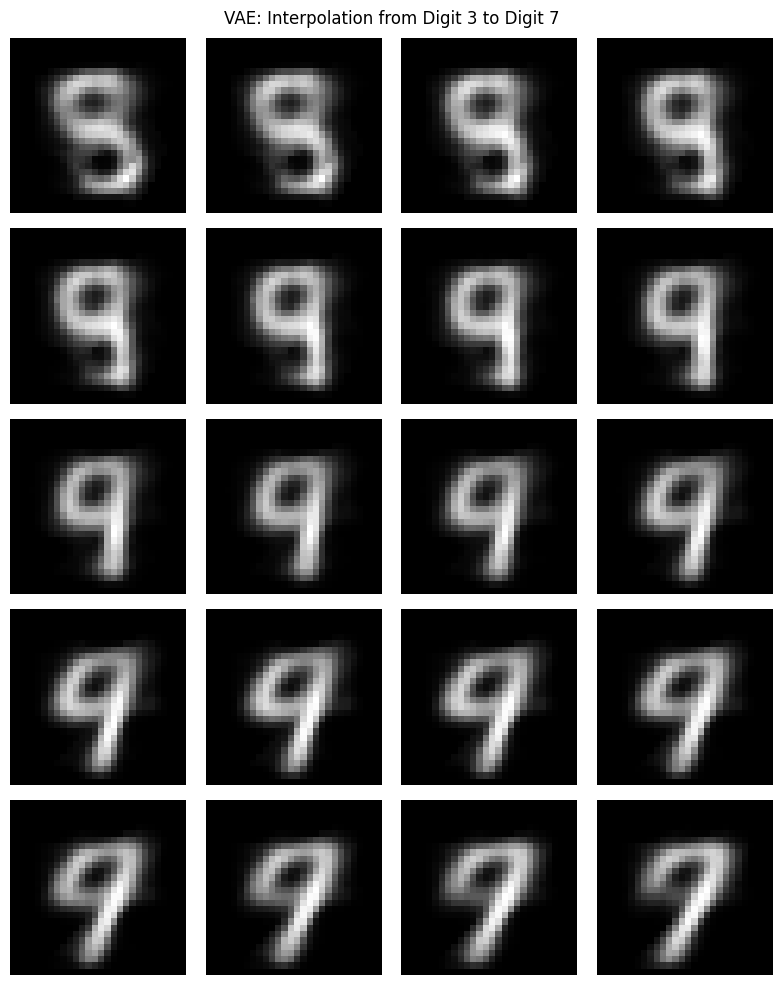

In [43]:
fig, axes = plt.subplots(5, 4, figsize=(8, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].cpu().squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("VAE: Interpolation from Digit 3 to Digit 7")
plt.tight_layout()
plt.show()